# Day 2 — PyTorch, Automatic Differentiation and Neural Networks

## How to use this notebook

This session connects **tensors → gradients → a neural-network layer → MNIST classification**. Work through the material in order; all activities and extensions are included.

- **CORE EXERCISE**: short priority tasks. Work on these first, with guidance from your demonstrator.
- **PROVIDED EXAMPLE**: code is already supplied; run it, inspect the output and answer the questions.
- **OPTIONAL EXERCISE**: longer implementations and experiments; attempt if time permits or after the session.

**Expected by the end:** interpret tensor shapes; explain what `requires_grad=True` and `.backward()` do; identify the forward → loss → gradient → parameter-update sequence; understand logits and predicted classes. If programming is new to you, it is fine to work with a neighbour and ask your group demonstrator.

**Before starting:** run cells from top to bottom. A CPU runtime is sufficient for the short examples. MNIST must be downloaded once; the full four-epoch training exercise may take longer on a laptop.

This notebook shows how to use PyTorch's (http://pytorch.org/) autodifferentiation, and also trains a simple classifier on the MNIST dataset.

### PROVIDED EXAMPLE

Run the tensor examples. **Warm-up:** in `torch.Size([100, 3, 200, 200])`, 100 is the number of images, 3 is the number of channels, and 200 × 200 are spatial dimensions. Indexing begins at 0.

## Part 1: Tensors

We start by importing `torch`.

In [1]:
import torch

Tensors, or multi-dimensional arrays, are the basic unit in PyTorch. Let's create a tensor with shape (3, 5, 3). `torch.randn` fills it with random values. An image batch is also a tensor, but with more dimensions.

In [2]:
x = torch.randn(3,5,3)
print(x)

tensor([[[-0.4139,  0.9352, -0.6941],
         [-0.1947, -0.0624, -0.5612],
         [ 0.8708,  0.1388, -0.1913],
         [-1.4111, -1.1468, -0.0337],
         [-0.4119, -0.4696, -2.0007]],

        [[ 0.5786,  1.1040,  1.0217],
         [-0.3450,  1.6553,  0.9588],
         [-1.0639, -2.0623, -1.3357],
         [-0.9200, -1.3161,  2.0834],
         [-0.0419,  1.1900,  0.3187]],

        [[ 1.0298, -0.1470,  0.1610],
         [ 1.7214, -0.7461,  1.3236],
         [-0.4843,  1.5100,  0.9877],
         [ 0.2824,  0.5153,  0.8402],
         [-0.9610, -0.9884, -1.2807]]])


### Slicing

It is common to have higher-dimensional tensors, to hold all aspects of your data together, such as a 3x200x200 tensor holding the R,G,B channels of an image of 200x200 pixels, or a 100x3x200x200 tensor to hold a batch of 100 such images.

We use slicing operations to view specific subtensors of such a tensor. Note that PyTorch uses zero-based indexing and row-major memory ordering.

In [3]:
# 100 images of 3 channels of size 200x200
x = torch.Tensor(100,3,200,200)
print(x.size())

# Second channel of the first image
y = x[0,1]
print(y.size())

torch.Size([100, 3, 200, 200])
torch.Size([200, 200])


### Numpy conversion

You might have noticed that Tensors are very similar to Numpy's ndarrays. In fact you can easily convert between ndarrays and Tensors.

In [4]:
x_np = x.numpy()
print(x_np.shape)

x = torch.from_numpy(x_np)
print(x.size())

(100, 3, 200, 200)
torch.Size([100, 3, 200, 200])


### A note on GPU usage

PyTorch is frequently used with a CUDA backend on a GPU. One would convert between tensors and CUDA tensors by simply calling

`x.cuda()`

`x.cpu()`

which transfer data to and from a GPU memory.

You can check if CUDA is available by using:

In [5]:
torch.cuda.is_available()

False

### PROVIDED EXAMPLE

Automatic differentiation computes gradients through the operations that produced a scalar result. Follow the example first; then complete one independent one-line exercise.

## Part 2: Automatic differentiation

PyTorch implements reverse-mode automatic differentiation (AD).

With AD, obtaining a gradient of a scalar-valued function is straightforward. Let's use the regular Python language features to define a function.

In [6]:
def f(x):
    y = torch.log(x[0]) + torch.sin(x[1])
    return x[2] * torch.exp(y)

Let's evaluate the gradient of `f(x)` at `x = [2,3,4]`.

In [7]:
x = torch.tensor([2.,3,4], requires_grad=True)
y = f(x)
print(y)

y.backward()# evaluates the gradient of y wrt to the graph leaves (x in this case)
print(x.grad)# gradients are accumulated in the .grad attribute of the leaf tensors

tensor(9.2125, grad_fn=<MulBackward0>)
tensor([ 4.6063, -9.1203,  2.3031])


Note that we get the function evaluated `f(2,3,4)` as `9.2125` and the gradient `f'(2,3,4)` as `[4.6063, -9.1203, 2.3031]`.

Also note the use of `requires_grad = True` for tagging the tensor `x` for being differentiated with respect to. This is for efficiency reasons, allowing PyTorch to ignore the bookkeeping for tensors whose derivatives we don't need.

**Try to explain:** `requires_grad=True` asks PyTorch to track operations on `x`; `backward()` computes how the scalar output changes with each component of `x`. When you call `backward()` again, gradients accumulate unless you reset them.

In [8]:
y = f(x)
y.backward()
print(x.grad)# note, the grad attribute is not reset every time .backward is called, 
# so it can accumulate if you are not careful! (see more here: https://pytorch.org/docs/stable/autograd.html)

tensor([  9.2125, -18.2406,   4.6063])


### CORE EXERCISE 1/3

**Task 1:** Compute the gradient of $y=(w-3)^2$ at $w=2$. The result should be $-2$. You have just seen how `.backward()` works in the preceding example.

In [9]:
w = torch.tensor(2.0, requires_grad=True)
y_toy = (w - 3) ** 2
y_toy.backward()
print("Gradient at w=2:", w.grad)


Gradient at w=2: tensor(-2.)


**solution**

`y_toy.backward()` populates `w.grad` with $2(w-3)=-2$. Unlike manually differentiating a whole neural network, we only specify the forward expression.

### PROVIDED EXAMPLE

A neural-network layer will combine matrix multiplication and a nonlinear activation. Focus on **input shapes and output shapes**, not memorising the API.

## Part 3: Neural networks

The previous two parts, namely defining and using tensors and being able to obtain derivatives, give us everything needed for constructing and training a neural network.

### Defining a neural network

A very important point to note is that **neural networks are just functions, and there is nothing special about them.**

A neural network is a series of linear algebra operations interleaved with non-linear transformations. Let's create a single feed-forward layer with two neurons connected to four inputs (note that this omits the bias term for simplicity).

In [10]:
def run_layer(weights, inputs):
    outputs = torch.mm(weights, inputs)
    outputs = torch.tanh(outputs)
    return outputs

W = torch.randn(2,4, requires_grad=True) # A 2x4 weight matrix
x = torch.tensor([[1.],[2],[3],[4]]) # A column vector of length four

y = run_layer(W, x)
print(y)

tensor([[ 0.8780],
        [-1.0000]], grad_fn=<TanhBackward0>)


### The loss function

Training this neural network layer would simply mean taking the derivative of a loss function at its output with respect to its trainable weights (the matrix `W` above).

In [11]:
def loss(outputs, targets):
    return torch.mean((outputs - targets)**2)

W = torch.randn(2,4, requires_grad=True) # A 2x4 weight matrix
x = torch.tensor([[1.],[2],[3],[4]]) # A column vector of length four

loss_value = loss(run_layer(W, x), torch.tensor([[1.],[1.]]))
print(loss_value)

loss_value.backward()

W_grad = W.grad
print(W_grad)

tensor(0.0001, grad_fn=<MeanBackward0>)
tensor([[-4.7776e-09, -9.5551e-09, -1.4333e-08, -1.9110e-08],
        [-4.8324e-04, -9.6648e-04, -1.4497e-03, -1.9330e-03]])


### Optimization

We would then iteratively update the weights in a gradient-based update rule.

In [12]:
learning_rate = 0.000001
W = W - learning_rate * W_grad
print(W)

tensor([[ 1.3578, -0.5199,  0.1773,  1.1150],
        [ 0.6771,  0.0582, -0.0944,  0.4781]], grad_fn=<SubBackward0>)


By taking the gradient of a neural network with respect to its trainable parameters (weights), we can optimize it with gradient descent.

### PROVIDED EXAMPLE

The next example uses PyTorch building blocks to define a convolutional classifier. It is not necessary to implement a CNN from scratch today.

## Using torch.nn modules

In practice, unless you are implementing new neural network architectures, you would use the existing neural network building blocks provided by the `torch.nn` module, which internally work similar to the basic example we covered above.

We will now define a convolutional neural network for image recognition on the MNIST dataset and train and test it, using the regular PyTorch workflow. The MNIST dataset is a collection of 60,000 images of handwritten digits labeled as belonging to one of the ten digit categories.

First we load the MNIST dataset. We also apply preprocessing for normalizing data.

We divide the data into training and test sets.

In [13]:
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

train_dataset = datasets.MNIST('./data', train=True, download=True,
                   transform=transforms.Compose([
                       transforms.ToTensor(),
                       transforms.Normalize((0.1307,), (0.3081,))
                   ]))

test_dataset = datasets.MNIST('./data', train=False, download=True,
                   transform=transforms.Compose([
                       transforms.ToTensor(),
                       transforms.Normalize((0.1307,), (0.3081,))
                   ]))

### PROVIDED EXAMPLE

Run the example below first to see how to display an MNIST image and its label.

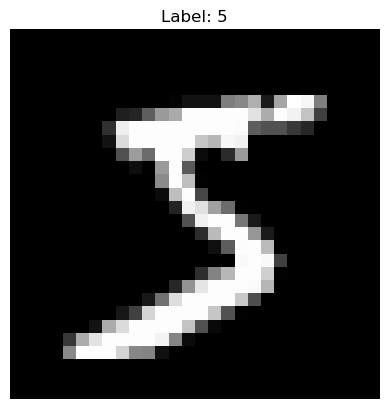

In [14]:
import matplotlib.pyplot as plt
# Small visualisation example (provided):
example_image, example_label = train_dataset[0]
plt.imshow(example_image[0], cmap="gray")
plt.title(f"Label: {example_label}")
plt.axis("off")
plt.show()

### CORE EXERCISE 2/3

**Task 2:** Write some code to visualise some of the training examples and their labels. Use `plt.imshow(...)` to display another MNIST example and inspect its label (about 10 minutes).

> **Question**: how many examples are there in the training and test datasets?

60000
10000


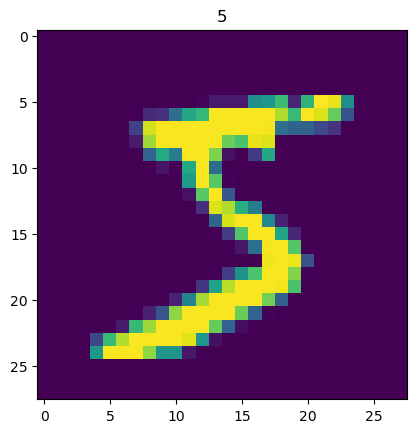

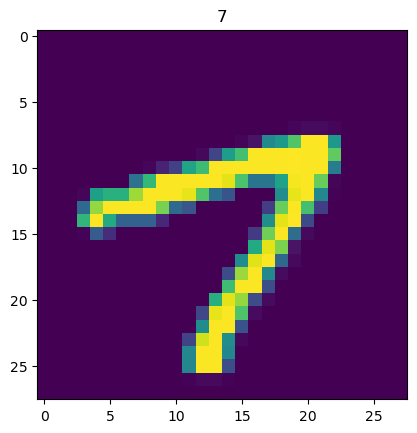

In [15]:
import matplotlib.pyplot as plt
import numpy as np


print(len(train_dataset))
print(len(test_dataset))

for i in [0, 101]:
    im,label = train_dataset[i]
    
    plt.imshow(im.numpy()[0])
    plt.title(label)
    plt.show()

**solution**

The MNIST training set has **60,000** examples and the test set has **10,000**. Images are 28 × 28 grayscale pixel arrays; each label is an integer from 0 to 9. The code in the preceding exercise displays example images and their labels.

Next we define our neural network composed of two convolutional layers followed by max-pooling layers and two fully-connected (linear) layers.

Note that we only need to 
- create the layer modules (in the `__init__` constructor) and 
- define the function for the forward run of the network (in the `forward` method)

In [16]:
import torch.nn as nn
import torch.nn.functional as F

class Net(nn.Module):
    def __init__(self): # The definition of neural network layers
        super(Net, self).__init__()
        self.conv1 = nn.Conv2d(1, 10, kernel_size=5)
        self.conv2 = nn.Conv2d(10, 20, kernel_size=5)
        self.fc1 = nn.Linear(320, 50)
        self.fc2 = nn.Linear(50, 10)

    def forward(self, x): # The function for forward evaluation
        x = F.relu(F.max_pool2d(self.conv1(x), 2))
        x = F.relu(F.max_pool2d(self.conv2(x), 2))
        x = x.view(-1, 320)
        x = F.relu(self.fc1(x))
        x = F.dropout(x, training=self.training)
        x = self.fc2(x)
        return x
    
model = Net()

> **Question**: What are the dimensions of the inputs and outputs of `model(x)`? What are the dimensions of its hidden layers?

**solution**

For a batch of size $B$, the input to `model(x)` is `(B, 1, 28, 28)` and the output logits are `(B, 10)` (one score per digit). Intermediate sizes are:

- `conv1`: `(B, 10, 24, 24)`; first max-pooling: `(B, 10, 12, 12)`.
- `conv2`: `(B, 20, 8, 8)`; second max-pooling: `(B, 20, 4, 4)`.
- Flatten: `(B, 320)`; `fc1`: `(B, 50)`; `fc2`: `(B, 10)`.

The `10` output values are **logits**, not probabilities. `softmax(dim=1)` converts them to class probabilities; the predicted label is the index of the largest logit (equivalently, the largest softmax probability).

Finally we train the network.
We use the stochastic gradient descent (SGD) optimization routine provided by the `torch.optim` module. We use a learning rate of `0.0001` and a momentum of `0.9`.

In [17]:
from torch import optim

optimizer = optim.SGD(model.parameters(), lr=0.0001, momentum=0.9)

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)# this automatically batches up examples, adding a batch dimension
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=True)

### CORE EXERCISE 3/3

**Task 3:** Use the provided model to compute cross-entropy loss on one batch. `batch_logits` has shape `(B, 10)` and `batch_labels` has shape `(B,)`. Pass raw **logits** directly to `F.cross_entropy` (it handles the softmax/log calculation internally).

In [18]:
batch_images, batch_labels = next(iter(train_loader))
batch_logits = model(batch_images)
batch_loss = F.cross_entropy(batch_logits, batch_labels)
print("Logits shape:", tuple(batch_logits.shape))
print("Cross-entropy loss:", batch_loss.item() if batch_loss is not None else "Complete Core 3")

Logits shape: (64, 10)
Cross-entropy loss: 2.339930534362793


**solution**

Use `F.cross_entropy(batch_logits, batch_labels)`. It takes **unnormalised logits** and integer category labels. Only apply `softmax` explicitly when you want to display probabilities; passing softmax values into cross-entropy would count the transformation twice.

### PROVIDED EXAMPLE

**Short end-to-end example.** This mini-demo trains for only a few batches so everybody can see the whole forward → loss → backward → update loop. It deliberately does **not** replace the complete train/test implementation exercise that follows. Accuracy after very few updates may remain low.

In [19]:
# A short, independently runnable demonstration (not the full training task).
demo_optimizer = optim.SGD(model.parameters(), lr=0.01, momentum=0.9)
model.train()
for step, (demo_x, demo_y) in enumerate(train_loader):
    demo_optimizer.zero_grad()
    demo_logits = model(demo_x)
    demo_loss = F.cross_entropy(demo_logits, demo_y)
    demo_loss.backward()
    demo_optimizer.step()
    if step == 7:  # eight small updates, not a full epoch
        break
model.eval()
with torch.no_grad():
    demo_test_x, demo_test_y = next(iter(test_loader))
    demo_preds = model(demo_test_x).argmax(dim=1)
    demo_accuracy = (demo_preds == demo_test_y).float().mean().item()
print(f"Mini-demo: last batch loss={demo_loss.item():.3f}, first test-batch accuracy={demo_accuracy:.1%}")

Mini-demo: last batch loss=2.268, first test-batch accuracy=15.6%


### OPTIONAL EXERCISE

**Training and evaluation functions.** This longer coding task is useful practice with dataloaders, gradients, optimisers and evaluation, but is **not** required to finish during the two-hour practical. You can use the preceding mini-demo as a guide.

**Task 4:** write two functions to train and test the network. 

Note: for classification, `model(x)` returns logits. Use `F.cross_entropy(model(x), labels)` **without first applying softmax**. When you need probabilities for visualisation, use `model(x).softmax(dim=1)`.

In [20]:
def train(epoch):
    model.train()
    
    
    # pseudocode:
    
    # for each batch in train_loader
        # carry out a forward pass of the network
        # compute the loss function (use cross-entropy)
        # compute the gradient wrt to the network weights
        # carry out an optimisation step (hint: you can use optimizer.step())
        # after every 100 batches, print out the current epoch number, batch number and loss value
    
    for batch_idx, (data, target) in enumerate(train_loader):
        optimizer.zero_grad()
        output = model(data)
        loss = F.cross_entropy(output, target)
        loss.backward()
        optimizer.step()
        if batch_idx % 100 == 0:
            print('Train Epoch: {} [{}/{} ({:.0f}%)]\tLoss: {:.6f}'.format(
                epoch, batch_idx * len(data), len(train_loader.dataset),
                100. * batch_idx / len(train_loader), loss.item()))
            
def test():
    model.eval()
    
    
    # pseudocode:
    
    # print out the test loss value averaged over the whole test dataset
    # assuming the class with the highest predicted probability as the predicted label,
    # print the fraction of correctly predicted labels (accuracy) over the whole test dataset
    
    test_loss = 0
    correct = 0
    for data, target in test_loader:
        output = model(data)
        test_loss += F.cross_entropy(output, target, reduction='sum').item()
        pred = output.max(dim=1)[1] # get the index of the max probability
        correct += pred.eq(target).cpu().sum()
        
    test_loss /= len(test_loader.dataset)
    print('\nTest set: Average loss: {:.4f}, Accuracy: {}/{} ({:.0f}%)\n'.format(
        test_loss, correct, len(test_loader.dataset),
        100. * correct / len(test_loader.dataset)))

**solution**

For each training batch: `optimizer.zero_grad()` → `model(data)` → `F.cross_entropy(output, target)` → `loss.backward()` → `optimizer.step()`. In evaluation use `model.eval()` and `torch.no_grad()`, accumulate the mean loss and compare `output.argmax(dim=1)` with targets. The complete implementations are in the preceding code cell.

### OPTIONAL EXERCISE

**Full four-epoch training.** Run this only **after** completing Task 4 in the previous code cell. The short provided training demonstration above already illustrates the key steps.

We train the neural network for four epochs in the extended exercise. As training progresses, classification accuracy on held-out images may improve. The exact accuracy depends on the learning rate, random initialisation, number of epochs and device. For choosing hyperparameters in real projects, use a separate **validation** set; reserve the **test** set for final evaluation.

In [21]:
for epoch in range(1, 5):
    train(epoch)
    test()

Train Epoch: 1 [0/60000 (0%)]	Loss: 2.268766
Train Epoch: 1 [6400/60000 (11%)]	Loss: 2.299546
Train Epoch: 1 [12800/60000 (21%)]	Loss: 2.249229
Train Epoch: 1 [19200/60000 (32%)]	Loss: 2.248912
Train Epoch: 1 [25600/60000 (43%)]	Loss: 2.257225
Train Epoch: 1 [32000/60000 (53%)]	Loss: 2.246183
Train Epoch: 1 [38400/60000 (64%)]	Loss: 2.237635
Train Epoch: 1 [44800/60000 (75%)]	Loss: 2.226094
Train Epoch: 1 [51200/60000 (85%)]	Loss: 2.095999
Train Epoch: 1 [57600/60000 (96%)]	Loss: 2.194952

Test set: Average loss: 2.1301, Accuracy: 4442/10000 (44%)

Train Epoch: 2 [0/60000 (0%)]	Loss: 2.152960
Train Epoch: 2 [6400/60000 (11%)]	Loss: 2.089427
Train Epoch: 2 [12800/60000 (21%)]	Loss: 2.058212
Train Epoch: 2 [19200/60000 (32%)]	Loss: 2.049116
Train Epoch: 2 [25600/60000 (43%)]	Loss: 2.050704
Train Epoch: 2 [32000/60000 (53%)]	Loss: 1.952043
Train Epoch: 2 [38400/60000 (64%)]	Loss: 1.820611
Train Epoch: 2 [44800/60000 (75%)]	Loss: 1.780856
Train Epoch: 2 [51200/60000 (85%)]	Loss: 1.703616
T

Let's test some images from the test set. You can evaluate the same cell many times to visualize results for more test images.

### OPTIONAL EXERCISE

**Prediction visualisation.** Explore model probabilities for a test image once you have a trained model.

**Task 5:** write some code to visualise the predicted class probabilites for some of the test images.

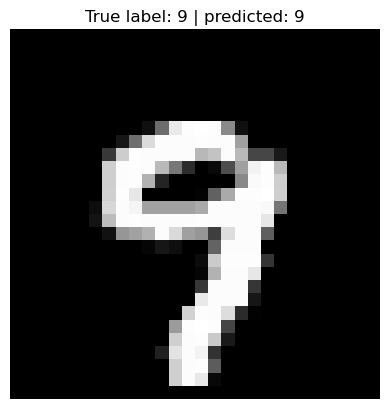

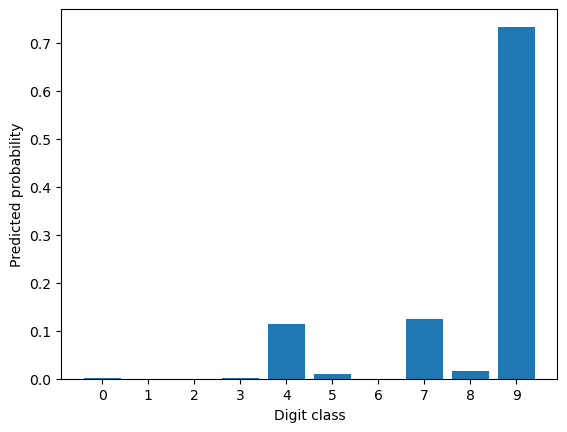

In [22]:
# Display one image and its predicted class probabilities.
example_images, example_labels = next(iter(test_loader))
test_image, test_label = example_images[0], example_labels[0]
model.eval()
with torch.no_grad():
    probabilities = model(test_image.unsqueeze(0)).softmax(dim=1)[0].cpu().numpy()
plt.imshow(test_image[0].cpu().numpy(), cmap="gray")
plt.title(f"True label: {int(test_label)} | predicted: {int(np.argmax(probabilities))}")
plt.axis("off")
plt.show()
plt.bar(range(10), probabilities)
plt.xticks(range(10))
plt.xlabel("Digit class")
plt.ylabel("Predicted probability")
plt.show()

**solution**

`softmax(dim=1)` turns ten logits into non-negative values that sum to one. Use the highest-scoring class as the predicted digit; the display may differ across runs because training and minibatch order are stochastic.

### OPTIONAL EXERCISE

Keep the three architecture / optimizer / learning-rate extensions; they are not part of the two-hour completion target.

## Extensions

> **Extension 1**: change the network design by adding dropout layers after the convolutional layers. How does this affect performance?

> **Extension 2**: Use the Adam optimiser instead of SGD, how does this affect performance?

> **Extension 3**: How high can the learning rate go before training becomes unstable?

**solution — Extension 1 (dropout):** In `Net.forward`, one option is `x = F.dropout2d(x, p=0.25, training=self.training)` after a convolutional block. Dropout randomly suppresses activations during training and may reduce overfitting; whether test accuracy improves depends on the data, rate, and training duration. Re-run with matched seeds to compare fairly.

**solution — Extension 2 (Adam):** Replace the SGD optimiser with `optim.Adam(model.parameters(), lr=1e-3)`, train a fresh model with the same evaluation protocol, and compare learning curves. Adam often converges faster at default settings, but superiority is not guaranteed.

**solution — Extension 3 (learning rate):** Sweep e.g. `1e-4`, `1e-3`, `1e-2`, `1e-1` (and higher only as an experiment), resetting model and optimiser for each run. Large learning rates can cause unstable or divergent training. There is no universal maximum; identify it from observed loss behaviour.

**Evaluation note:** Use a separate validation split for architecture and learning-rate comparisons rather than repeatedly selecting on the test set.